# Pan Dulce - El PDK y el transistor **Kit Kat** (GT2N 2nm)

En la Capsula 1 vemos el **PDK** (el contrato con la fabrica). Hoy usamos
**GT2N**, un PDK abierto de **2 nm**, para asomarnos a lo ultimo: sus
transistores son **GAAFET nanosheet** -- laminas de silicio apiladas, igual
que las obleas de chocolate de un **Kit Kat**.

> Aqui no corremos un flujo de 2 nm (eso es teorico): lo que hacemos es **ver**
> por que el transistor moderno se ve asi. Corre las celdas en orden.

## 1 - Preparar (solo graficas, sin instalar nada)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from matplotlib.animation import FuncAnimation
from ipywidgets import interact, IntSlider
from IPython.display import HTML
print('listo')

listo


## 2 - La evolucion del transistor

El reto siempre es el mismo: que la **compuerta** controle bien el **canal**
por donde pasa la corriente. Mientras mas lo rodea, mejor lo controla (menos
fugas). Por eso el transistor fue cambiando de forma:

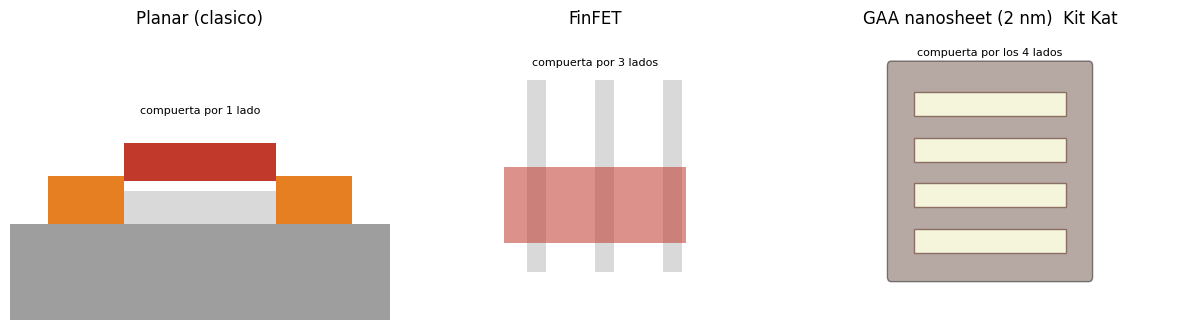

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
S, D, GATE, CH = '#e67e22', '#e67e22', '#c0392b', '#d9d9d9'

# --- Planar ---
ax = axes[0]; ax.set_title('Planar (clasico)'); ax.axis('off')
ax.set_xlim(0, 10); ax.set_ylim(0, 6)
ax.add_patch(Rectangle((0, 0), 10, 2, fc='#9e9e9e'))          # cuerpo
ax.add_patch(Rectangle((1, 2), 2, 1, fc=S))                   # fuente
ax.add_patch(Rectangle((7, 2), 2, 1, fc=D))                   # drenaje
ax.add_patch(Rectangle((3, 2), 4, 0.7, fc=CH))               # canal
ax.add_patch(Rectangle((3, 2.9), 4, 0.8, fc=GATE))          # compuerta arriba
ax.text(5, 4.3, 'compuerta por 1 lado', ha='center', fontsize=8)

# --- FinFET ---
ax = axes[1]; ax.set_title('FinFET'); ax.axis('off')
ax.set_xlim(0, 10); ax.set_ylim(0, 6)
for x in (3.2, 5.0, 6.8):
    ax.add_patch(Rectangle((x, 1), 0.5, 4, fc=CH))          # aletas paradas
ax.add_patch(Rectangle((2.6, 1.6), 4.8, 1.6, fc=GATE, alpha=0.55))  # compuerta las abraza
ax.text(5, 5.3, 'compuerta por 3 lados', ha='center', fontsize=8)

# --- GAA nanosheet ---
ax = axes[2]; ax.set_title('GAA nanosheet (2 nm)  Kit Kat'); ax.axis('off')
ax.set_xlim(0, 10); ax.set_ylim(0, 6)
ax.add_patch(FancyBboxPatch((2.4, 0.9), 5.2, 4.4, boxstyle='round,pad=0.1',
                            fc='#5d4037', alpha=0.45))        # compuerta envolvente
for k in range(4):
    ax.add_patch(Rectangle((3, 1.4 + k*0.95), 4, 0.5, fc='#f5f5dc', ec='#8d6e63'))
ax.text(5, 5.5, 'compuerta por los 4 lados', ha='center', fontsize=8)

plt.tight_layout(); plt.show()

## 3 - El Kit Kat se arma por capas

El GAAFET de 2 nm apila varias **laminas** (nanosheets) de silicio, una sobre
otra, y la compuerta las envuelve a todas. Velo armarse capa por capa:

In [ ]:
NS = 4                      # numero final de nanosheets
fig, ax = plt.subplots(figsize=(6, 4))

def draw(i):
    ax.clear(); ax.axis('off'); ax.set_xlim(0, 10); ax.set_ylim(0, 8)
    # region de compuerta (gate-all-around)
    ax.add_patch(FancyBboxPatch((2.6, 0.8), 4.8, 6.4, boxstyle='round,pad=0.1',
                                fc='#5d4037', alpha=0.4))
    # fuente y drenaje a los lados
    ax.add_patch(Rectangle((0.4, 0.8), 2.0, 6.4, fc='#e67e22'))
    ax.add_patch(Rectangle((7.6, 0.8), 2.0, 6.4, fc='#e67e22'))
    ax.text(1.4, 7.5, 'fuente', ha='center', fontsize=8)
    ax.text(8.6, 7.5, 'drenaje', ha='center', fontsize=8)
    n = min(i, NS)
    for k in range(n):
        ax.add_patch(Rectangle((2.3, 1.3 + k*1.4), 5.4, 0.7,
                               fc='#f5f5dc', ec='#8d6e63', lw=1.5))
    ax.set_title(f'nanosheets apilados: {n}   (las obleas del Kit Kat)')
    return []

anim = FuncAnimation(fig, draw, frames=NS + 3, interval=600)
plt.close(fig)
HTML(anim.to_jshtml())

## 4 - Juega: cuantas laminas?

Mas laminas apiladas = mas 'ancho' efectivo del canal = mas corriente, sin
ocupar mas area en el chip. Mueve el slider:

In [ ]:
def kitkat(n=3):
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(9, 3.6),
                                   gridspec_kw={'width_ratios': [1, 1.1]})
    # corte del transistor GAA con n laminas
    axL.axis('off'); axL.set_xlim(0, 6); axL.set_ylim(0, 8)
    axL.add_patch(FancyBboxPatch((1, 0.8), 4, 6.4, boxstyle='round,pad=0.1',
                                 fc='#5d4037', alpha=0.4))
    paso = 5.4 / max(n, 1)
    for k in range(n):
        axL.add_patch(Rectangle((1.6, 1.1 + k*paso), 2.8, min(0.5, paso*0.6),
                                fc='#f5f5dc', ec='#8d6e63', lw=1.5))
    axL.set_title(f'GAA con {n} nanosheet(s)\ncompuerta envolviendo cada lamina')
    # corriente relativa (cualitativo: ~ proporcional a # de laminas)
    axR.bar(['1 lamina', f'{n} laminas'], [1, n], color=['#bdbdbd', '#C8742B'])
    axR.set_ylim(0, 5.5); axR.set_ylabel('corriente de manejo (relativa)')
    axR.set_title('mas laminas -> mas corriente (cualitativo)')
    plt.tight_layout(); plt.show()

interact(kitkat, n=IntSlider(3, 1, 5, description='laminas'));

interactive(children=(IntSlider(value=3, description='laminas', max=5, min=1), Output()), _dom_classes=('widge…

## 5 - Bonus: y la energia por detras (BSPDN)

GT2N ademas usa **BSPDN** (backside power delivery): la energia llega por la
**parte de atras** de la oblea, dejando la cara de arriba libre para las
senales. Es otra innovacion de los nodos de 2 nm.

## Lo que sigue

Ya tenemos los ladrillos (celdas de 2 nm) y entendimos como es el transistor
por dentro. Lo siguiente: decirle al chip **que** hacer -> el **RTL** (Churros).